<a href="https://colab.research.google.com/github/ricvazquez/ColabFiles/blob/main/PracticaVES_273509.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Practica Validacion, Evaluacion y Seleccion

Nombre: Ricardo Vazquez Macias

Matricula: 273509

In [ ]:
pip install ucimlrepo

In [ ]:
## Primero hacemos los imports necesarios
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import make_scorer, f1_score

from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


In [ ]:
## Esta froma de traer el dataset lo sque directamente de la pagina
glioma_grading_clinical_and_mutation_features = fetch_ucirepo(id=759)
x = glioma_grading_clinical_and_mutation_features.data.features
y = glioma_grading_clinical_and_mutation_features.data.targets
print(x.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Gender            839 non-null    int64  
 1   Age_at_diagnosis  839 non-null    float64
 2   Race              839 non-null    object 
 3   IDH1              839 non-null    int64  
 4   TP53              839 non-null    int64  
 5   ATRX              839 non-null    int64  
 6   PTEN              839 non-null    int64  
 7   EGFR              839 non-null    int64  
 8   CIC               839 non-null    int64  
 9   MUC16             839 non-null    int64  
 10  PIK3CA            839 non-null    int64  
 11  NF1               839 non-null    int64  
 12  PIK3R1            839 non-null    int64  
 13  FUBP1             839 non-null    int64  
 14  RB1               839 non-null    int64  
 15  NOTCH1            839 non-null    int64  
 16  BCOR              839 non-null    int64  
 1

In [ ]:
## Revisamos la info que nos trajo el dataset
print(x.shape)
print(x.describe())

(839, 23)
           Gender  Age_at_diagnosis        IDH1        TP53        ATRX  \
count  839.000000        839.000000  839.000000  839.000000  839.000000   
mean     0.418355         50.935411    0.481526    0.414779    0.258641   
std      0.493583         15.702339    0.499957    0.492978    0.438149   
min      0.000000         14.420000    0.000000    0.000000    0.000000   
25%      0.000000         38.055000    0.000000    0.000000    0.000000   
50%      0.000000         51.550000    0.000000    0.000000    0.000000   
75%      1.000000         62.800000    1.000000    1.000000    1.000000   
max      1.000000         89.290000    1.000000    1.000000    1.000000   

             PTEN        EGFR         CIC       MUC16      PIK3CA  ...  \
count  839.000000  839.000000  839.000000  839.000000  839.000000  ...   
mean     0.168057    0.133492    0.132300    0.116806    0.087008  ...   
std      0.374140    0.340309    0.339019    0.321380    0.282015  ...   
min      0.000000 

In [ ]:
## Vemos cuantos valores diferentes trae Y y lo normalizamos
## Para saber que tan balanceado esta el dataset
print(y.value_counts())
print(y.value_counts(normalize=True)*100)

Grade
0        487
1        352
Name: count, dtype: int64
Grade
0        58.045292
1        41.954708
Name: proportion, dtype: float64


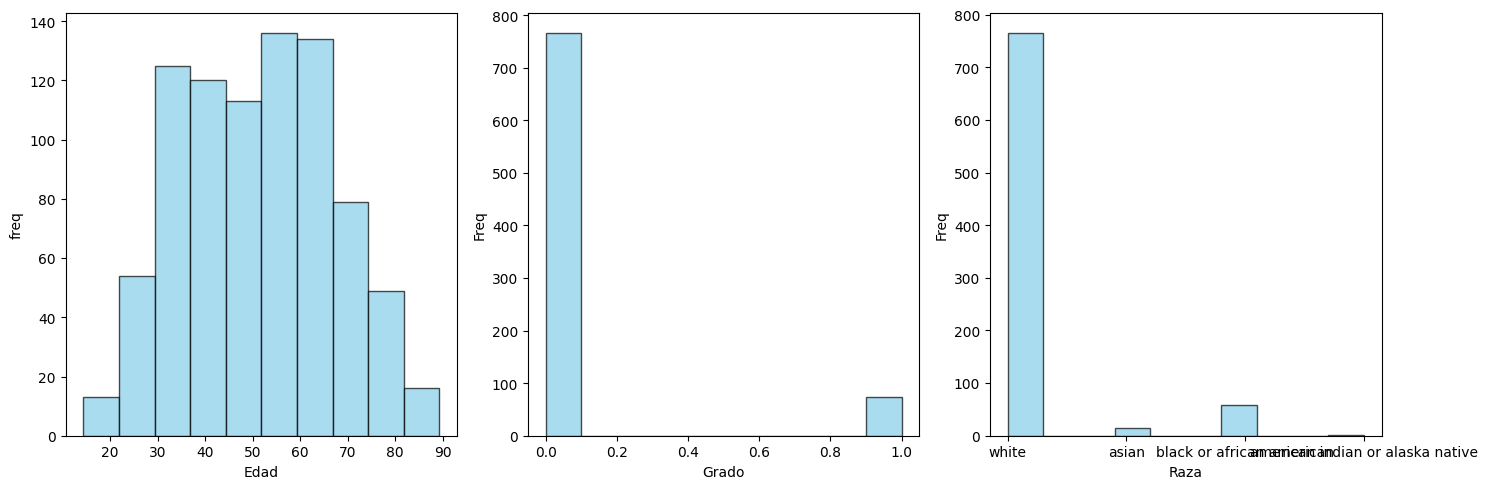

In [ ]:
## Graficamos edad, grado y raza del paciente, ya que son las que mas variabilidad iban a tener
## Las demas son categoricas de 0 y 1
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].hist(x.Age_at_diagnosis, color='skyblue', edgecolor='black', alpha=0.7)
axs[0].set_xlabel('Edad')
axs[0].set_ylabel('freq')
axs[1].hist(x.PIK3CA, color='skyblue', edgecolor='black', alpha=0.7)
axs[1].set_xlabel('Grado')
axs[1].set_ylabel('Freq')
axs[2].hist(x.Race, color='skyblue', edgecolor='black', alpha=0.7)
axs[2].set_xlabel('Raza')
axs[2].set_ylabel('Freq')
plt.tight_layout()
plt.show()

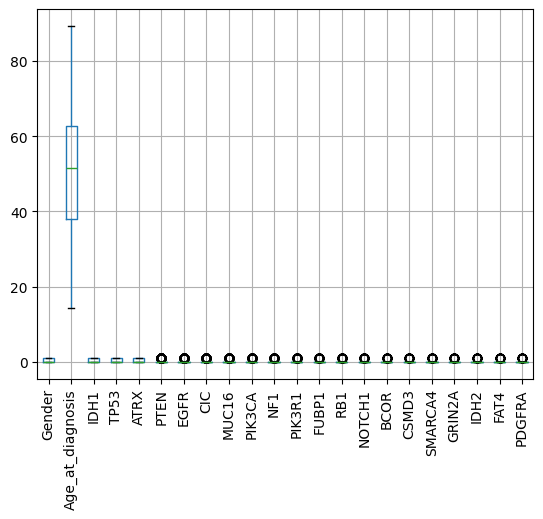

In [ ]:
## Hacemos los boxplot de todas las numericas
## Esteticamente no se vera muy bien porque las demas categorias tienen valores de 0 y 1
x.boxplot()
plt.xticks(rotation=90)
plt.show()

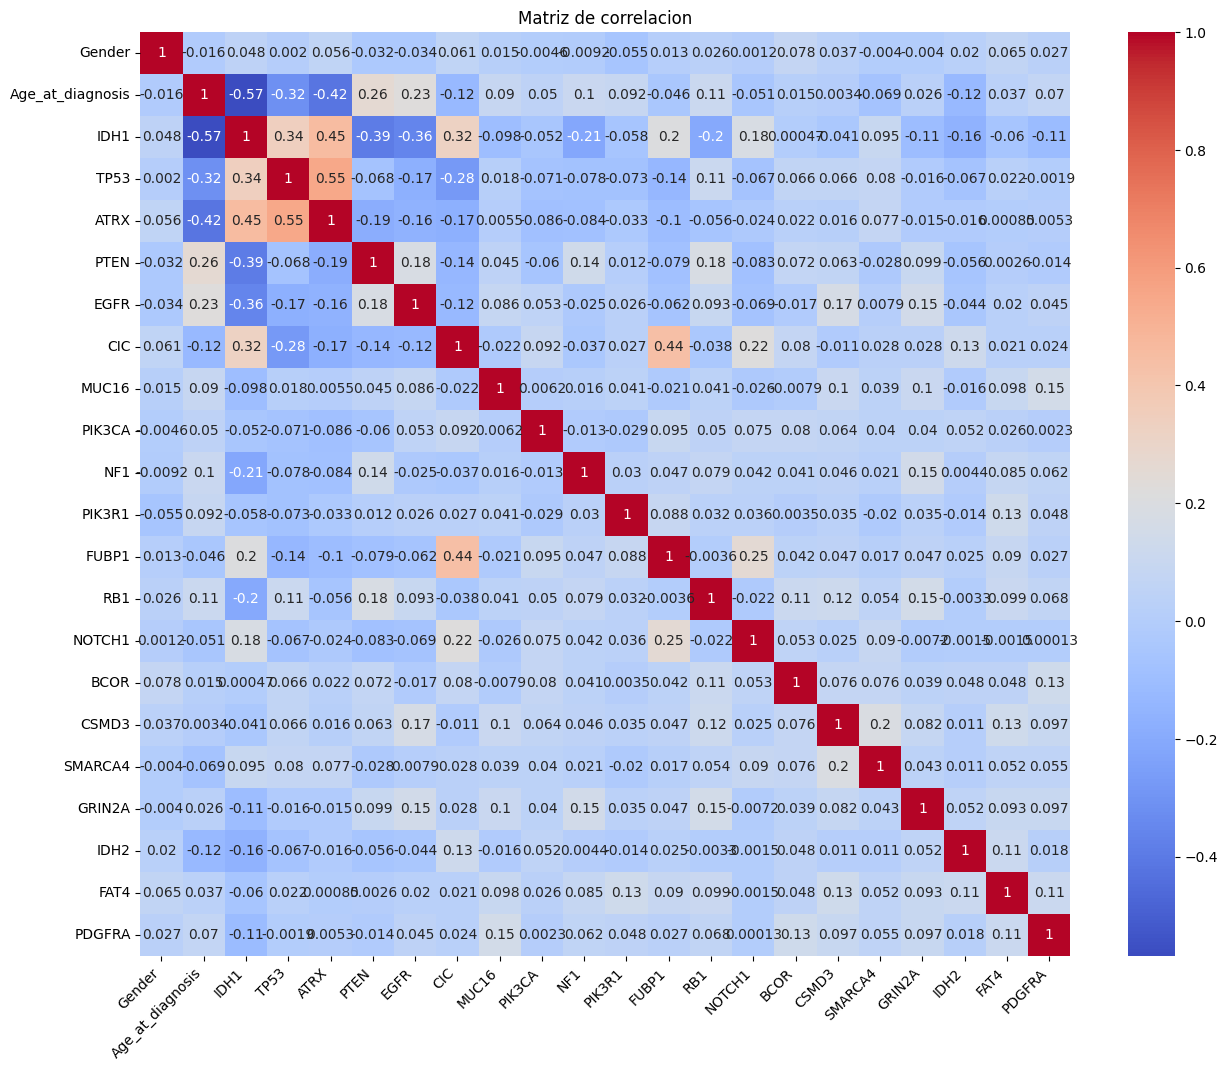

In [ ]:
## Hacemos el mapa de calor
mat = x.select_dtypes(include=[np.number])
matriz = mat.corr()
plt.figure(figsize=(15,12))
sns.heatmap(matriz, annot=True,cmap='coolwarm',)
plt.title('Matriz de correlacion')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()
plt.show()

## Reflexion

Podemos ver que realmente no hay mucha correlacion entre las mismas columnas, la correlacion mas alta, es la de TP53 con ATRX, que es de solo un 55%, todas las clases son de 0 y 1. Y como pudimos ver cuando revisamos las categorias de grade, el dataset no se ve desbalanceado esta a 58-41 de proporcion. Y me parece que la matriz no muestra claramente alguna correlacion importante de nuestra columna objetivo (PIK3CA)

In [ ]:
## revisamos que x no tenga nulos y nos quedamos unicamente con lo numerico
print(x.isna().sum())
x= pd.get_dummies(x)
print(x.shape)

Gender              0
Age_at_diagnosis    0
Race                0
IDH1                0
TP53                0
ATRX                0
PTEN                0
EGFR                0
CIC                 0
MUC16               0
PIK3CA              0
NF1                 0
PIK3R1              0
FUBP1               0
RB1                 0
NOTCH1              0
BCOR                0
CSMD3               0
SMARCA4             0
GRIN2A              0
IDH2                0
FAT4                0
PDGFRA              0
dtype: int64
(839, 26)


In [ ]:
y = y.astype(int)
print(y.dtypes)

Grade    int64
dtype: object


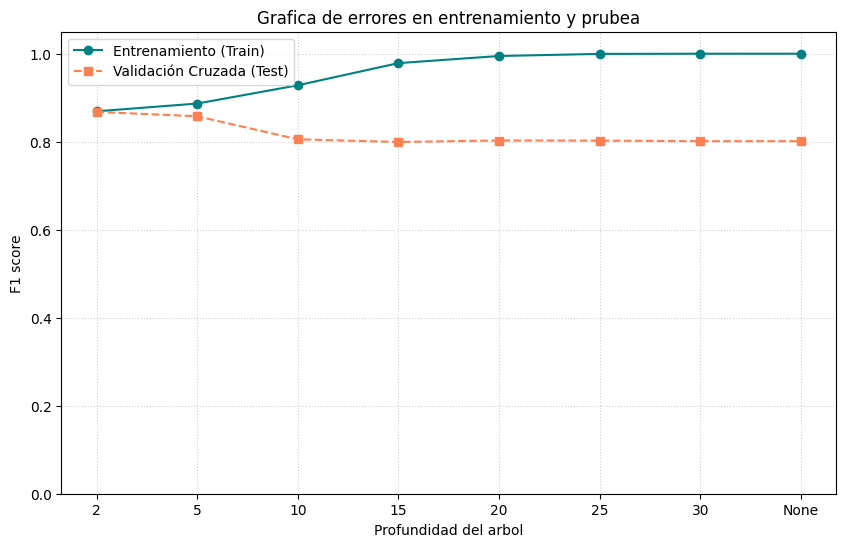

In [ ]:
## Creamos segun los parametros sugeridos en la practica
## Y graficamos lo obtenido que guardamos cada salto
prof = [2,5,10,15,20,25,30, None]
f1_t = []
f1_te= []
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=7)

for profi in prof:
  model = DecisionTreeClassifier(max_depth=profi, random_state=3)
  res = cross_validate(model, x, y, cv=skf, scoring='f1_macro', return_train_score=True)
  # print(res)
  f1_t.append(res['train_score'].mean())
  f1_te.append(res['test_score'].mean())

plt.figure(figsize=(10,6))
# plt.plot(prof, f1_t, label='train')
# plt.plot(prof, f1_te, label='test')
etiquetas_x = [str(d) if d is not None else 'None' for d in prof]

plt.plot(etiquetas_x, f1_t, marker='o', linestyle='-', label='Entrenamiento (Train)', color='teal')
plt.plot(etiquetas_x, f1_te, marker='s', linestyle='--', label='Validación Cruzada (Test)', color='coral')

plt.xticks(ticks=range(len(prof)), labels=etiquetas_x)
plt.title("Grafica de errores en entrenamiento y prubea")
plt.xlabel("Profundidad del arbol")
plt.ylabel("F1 score")
plt.ylim(0, 1.05)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

In [ ]:
## 4.- Optimizacion de hiperparametros
## Hacemos la optimizacion con lo sugerido en la practica
model2 = DecisionTreeClassifier(random_state=3)
dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),
    'min_samples_split': list(range(2, 21)),
}
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=7)
random_search = RandomizedSearchCV(model2, param_distributions=dist, n_iter=5, cv=skf, scoring='f1_macro',n_jobs=1, random_state=42)
random_search.fit(x,y)
print(random_search.best_params_)
print(random_search.best_score_)
print(np.sum(random_search.cv_results_['mean_score_time']) + np.sum(random_search.cv_results_['mean_fit_time']))

{'min_samples_split': 17, 'max_depth': 35, 'criterion': 'entropy'}
0.8314944771234474
0.13768723011016845


In [ ]:
## 5.- Optimizacion de hiperparametros con GridSearchCV
## Usamos el arbol y los parametros que guardamos arriba, pero ahora para grid
grid = GridSearchCV(model2, param_grid=dist, cv=skf, scoring='f1_macro', n_jobs=1)
grid.fit(x,y)
print(grid.best_params_)
print(grid.best_score_)
print(np.sum(grid.cv_results_['mean_score_time']) + np.sum(grid.cv_results_['mean_fit_time']))

{'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 13}
0.8637294941246895
25.363798642158507


In [ ]:
## 6.- Optimización de hiperparámetros con RandomizedSearchCV: Accuracy
## Ahora usamos el scoring de accuracy para random
rand_acc = RandomizedSearchCV(model2, param_distributions=dist, n_iter=5, cv=skf, scoring='accuracy', n_jobs=1, random_state=42)
rand_acc.fit(x,y)
print(rand_acc.best_params_)
print(rand_acc.best_score_)
print(np.sum(rand_acc.cv_results_['mean_score_time']) + np.sum(rand_acc.cv_results_['mean_fit_time']))

{'min_samples_split': 17, 'max_depth': 35, 'criterion': 'entropy'}
0.8367183017785427
0.06438531875610351


In [ ]:
## 7. Optimización de hiperparámetros con GridSearchCV: accuracy
## Usamos el scoring de accuracy para grid
grid_acc = GridSearchCV(model2, param_grid=dist, cv=skf, scoring='accuracy', n_jobs=1)
grid_acc.fit(x,y)
print(grid_acc.best_params_)
print(grid_acc.best_score_)
print(np.sum(grid_acc.cv_results_['mean_score_time']) + np.sum(grid_acc.cv_results_['mean_fit_time']))

{'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 13}
0.8653327596098681
19.524565958976744


8.Actividad de reflexión y análisis

### ¿Cuál método encontró mejores hiperparámetros?
Segun los score de cada una, parece ser que la que mejor hiperparametros dio, fue GridSearch con un scoring en accuracy

### ¿Cuál fue más costoso computacionalmente?
Como podemos verlo con los ccv result de tiempos, el que tardo mas tiempo y por ende costo mas computacionalmente, fue el grid search con metrica de f1 macro

### ¿Los resultados en f1_macro set fueron distintos en ambos métodos de optimización? ¿Por qué?
Si, la de grid search fue mas alta, ya que esta si prueba todas las combinaciones posibles, y si asegura encontrar la mejor combinacion a diferencia de random que solo encontrara la mejor combinacion de las que hizo al azar

### ¿Los resultados en accuracy set fueron distintos en ambos métodos de optimización? ¿Por qué?
Accuracy pudiera haberse visto afectado por el ligero desbalance que hay entre clases, accuracy no toma mucho en cuenta las fallas que pudieran verse en la clase chica, en cambio f1 si penaliza mas por las fallas que pudieras tener en ambas

### ¿Los valores de hiperpárametros fueron iguales en Accuracy y F1 Macro ?
Si, tanto en random com en grid, ambos hiperparametros fueron iguales, tomaron el mismo criterio y los saltos de profundidad (max_depth)